# Name That LLM Kaggle Competition: Classifying AI-Generated Text By Source Model

**Course:** Machine Learning   
**Author:** Connor Moquin, Weiya Wang, Walter Waverley  
**Date:** December 2026   

The dataset features text output from 18 frontier LLMs each responding to 150 prompts. Each response is between 40 and 250 words. The goal is to classify which texts came from which specific LLM model, and the main metric used for evaluation is balanced accuracy.

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import kagglehub

# import the kaggle competition dataset
path = kagglehub.competition_download('name-that-llm')
# store in dataframe
df = pd.read_csv(os.path.join(path, "train.csv"), index_col=0)
# print full texts if needed
pd.set_option("display.max_colwidth", None)

We chose to split training and testing data 80/20 by prompt so our model doesn't learn the prompt subject and instead focuses on the language and syntax style of the texts. Our initial baseline is applying a TF-IDF vectorizer to the inputs and training logistic regression. This produced a balanced accuracy of .25. With 18 balanced classes, the accuracy of guessing is .056, so TF-IDF is encoding some meaningful information.

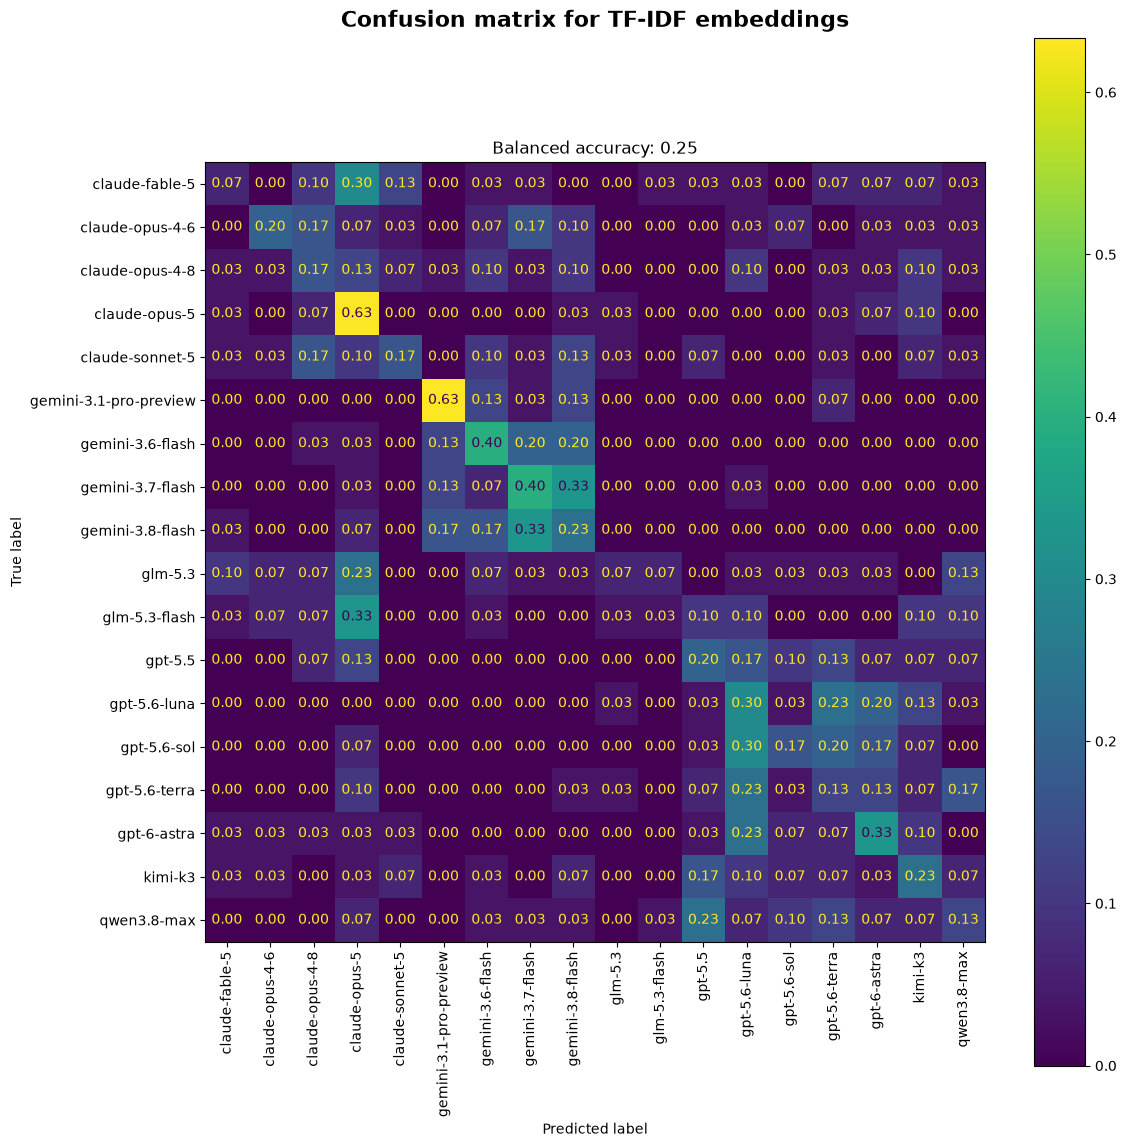

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay

# separate data and labels
X = df["text"]
y = df["model"]
# split train and test by prompt
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=df["prompt_id"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# vectorize inputs
vec = TfidfVectorizer()
X_train_vec = vec.fit_transform(X_train)
X_test_vec = vec.transform(X_test)
# apply logistic regression to vectorized input
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_vec, y_train)
# make prediction
y_pred = clf.predict(X_test_vec)
# calculate balanced accuracy
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation=90, normalize="true", values_format=".2f")
plt.suptitle("Confusion matrix for TF-IDF embeddings", fontsize=16, fontweight="bold")
plt.title("Balanced accuracy: " + str(round(balanced_accuracy, 4)))
plt.tight_layout()

Our first comparison to this baseline using a frozen BERT model with mean pooling to embed the inputs and again train logistic regression. This only resulted in a slightly better accuracy of .2833.

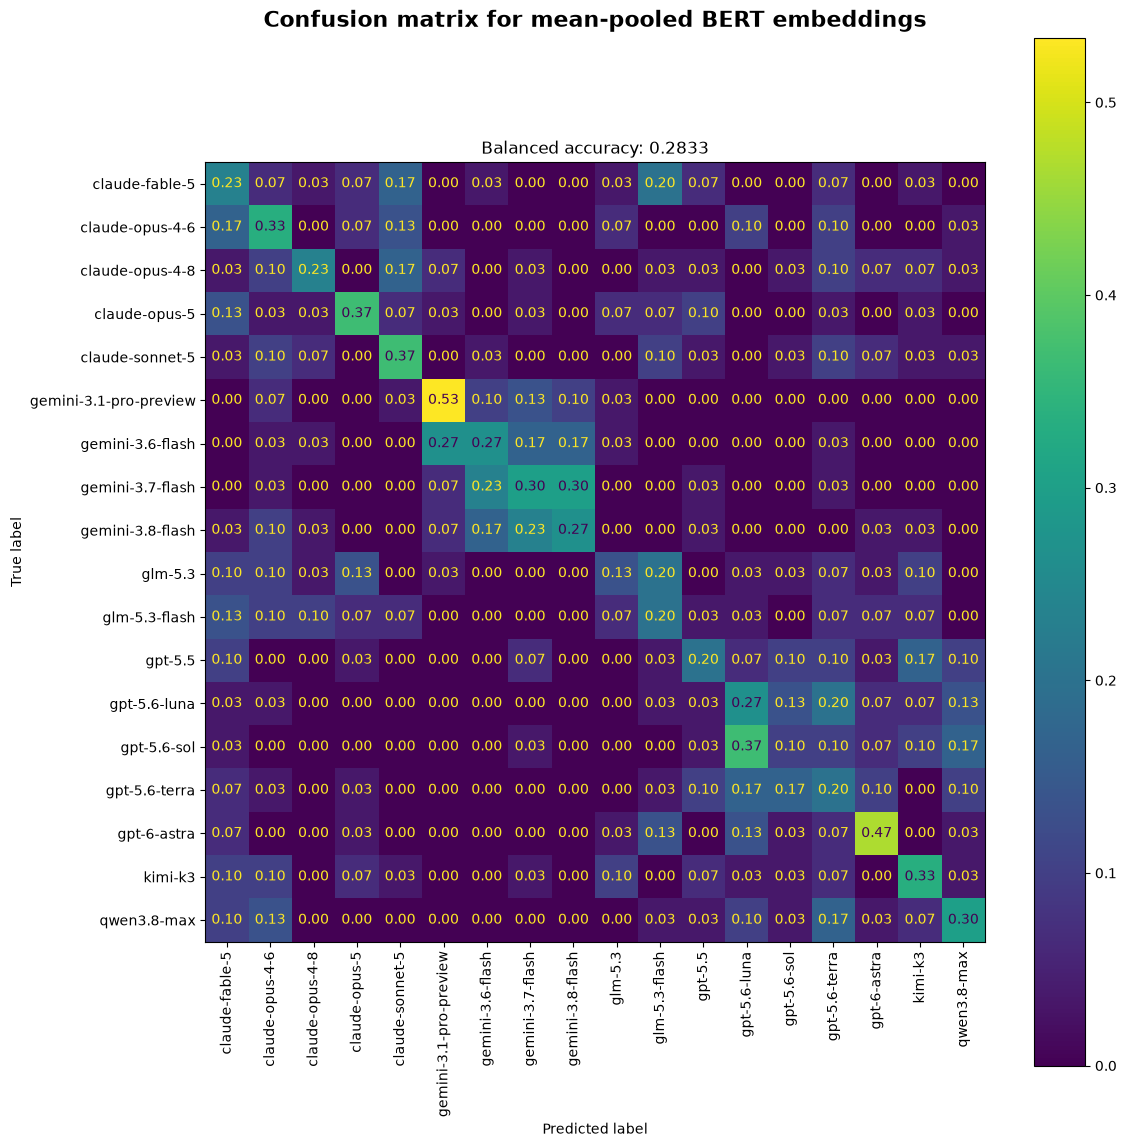

In [40]:
import torch
import transformers
from transformers import AutoTokenizer, AutoModel
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# hide transformer logs from notebook output
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()

# move model to CUDA or Metal Performance Shaders to improve speed
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
dtype = torch.float32 if device == "cpu" else torch.float16

# load BERT tokenizer and encoder
name = "bert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(name)
model = AutoModel.from_pretrained(name, dtype=dtype).to(device).eval()

# embeds texts into vectors using BERT, done in batches of 32 for efficiency
def embed(texts, batch_size=32, max_length=512):
    texts = texts.tolist()
    order = np.argsort([len(t) for t in texts]) # sort by text length to pad evenly
    out = np.zeros((len(texts), model.config.hidden_size), dtype=np.float32)
    for i in range(0, len(texts), batch_size):
        idx = order[i:i+batch_size]
        enc = tokenizer([texts[j] for j in idx], padding=True, truncation=True, 
                        max_length=max_length, return_tensors="pt").to(device)
        with torch.inference_mode(): # disable gradients for efficiency
            hidden = model(**enc).last_hidden_state
        # apply mean pooling, mask every padded position to zero
        mask = enc["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1)
        out[idx] = pooled.float().cpu().numpy()
    return out

# embed inputs
X_train_emb = embed(X_train)
X_test_emb = embed(X_test)

# fit logistic regression on BERT embeddings
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
clf.fit(X_train_emb, y_train)
y_pred = clf.predict(X_test_emb)
# calculate balanced accuracy
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation=90, normalize="true", values_format=".2f")
plt.suptitle("Confusion matrix for mean-pooled BERT embeddings", fontsize=16, fontweight="bold")
plt.title("Balanced accuracy: " + str(round(balanced_accuracy, 4)))
plt.tight_layout()